#DSN Bootcamp Qualification Hackathon 2026 ML Track

#LOAD-VISUALIZE/EDA UNDERSTAND - ANALYZE - MODEL- GET BEST MODEL - I BUILT FEATURE ENIGNEERING- PREPROCESSING , RETRAIN MODEL, MAKE MY FINAL PREDICTION.

# 1. LOAD THE STORE DATASET
**Goal:** I imported the raw dataset, verified its dimensions, and previewed its structure to ensure that it was loaded successfully.a successful load.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor,
    ExtraTreesRegressor
)

!pip install catboost

from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor, early_stopping, log_evaluation

RANDOM_STATE = 42

In [14]:
df = pd.read_csv("/data/train.csv")

In [15]:
df

,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales
0,row_00000,PRD-PRFP9S,14.252,Low Fat,0.0271,Frozen Foods,81.37,STORE-AGY,45,Large,Tier_3,Standard Supermarket,1764.98
1,row_00001,PRD-PXXK71,7.698,Low Fat,0.0720,HEALTH AND HYGIENE,42.05,STORE-YLW,35,Small,Tier_1,Standard Supermarket,342.13
2,row_00002,PRD-V5MOIJ,14.264,Regular,0.0421,Canned,41.35,STORE-89Z,33,Medium,Tier_1,Standard Supermarket,378.85
3,row_00003,PRD-UN5Z3J,NaN,Regular,0.0449,soft drinks,174.35,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket,5595.72
4,row_00004,PRD-6RDQYB,10.338,Regular,0.0120,meat,203.06,STORE-9RG,28,Small,Tier_2,Standard Supermarket,2375.36
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6813,row_08518,PRD-V56VKT,9.201,Regular,0.2851,Fruits and Vegetables,136.57,STORE-JOR,34,NaN,Tier_3,Corner Shop,276.50
6814,row_08519,PRD-S1AWP0,15.770,Low Fat,0.1193,FROZEN FOODS,74.03,STORE-OYG,25,NaN,Tier_2,Standard Supermarket,1265.63
6815,row_08520,PRD-NCP2VI,17.665,Low Fat,0.0182,Health and Hygiene,234.87,STORE-DKU,30,NaN,Tier_2,Standard Supermarket,6254.55
6816,row_08521,PRD-K9LSG4,20.645,Low Fat,0.0567,snack foods,118.86,STORE-OYG,25,NaN,Tier_2,Standard Supermarket,1658.06


### 1.1 Data Cleaning
**Goal:** I dropped unique identifiers (`id`) to prevent overfitting and ensure the model learns generalizable patterns rather than memorizing specific rows.

In [16]:
df = df.drop(["id"], axis=1, errors='ignore')

In [17]:
# I inspected the data types and identified missing values across all features to assess data consistency and completeness.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6818 entries, 0 to 6817
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_code         6818 non-null   object 
 1   product_weight_kg    5593 non-null   float64
 2   fat_content          6818 non-null   object 
 3   shelf_visibility     6818 non-null   float64
 4   product_category     6818 non-null   object 
 5   product_price        6818 non-null   float64
 6   store_code           6818 non-null   object 
 7   store_age_years      6818 non-null   int64  
 8   store_size           4899 non-null   object 
 9   store_location_tier  6818 non-null   object 
 10  store_format         6818 non-null   object 
 11  total_sales          6818 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 639.3+ KB


In [18]:
# I quantified the exact number of duplicate records to verify data integrity and ensure that no identical observations were unintentionally repeated.
df.describe()

,product_weight_kg,shelf_visibility,product_price,store_age_years,total_sales
count,5593.000000,6818.000000,6818.000000,6818.000000,6818.000000
mean,12.850876,0.065527,140.473623,34.178205,2174.756574
std,4.646542,0.051566,62.413513,8.384574,1697.894956
min,4.482000,0.000000,31.110000,23.000000,32.700000
25%,8.750000,0.026600,93.280000,28.000000,834.792500
50%,12.647000,0.053200,142.065000,33.000000,1790.890000
75%,16.894000,0.093400,185.987500,45.000000,3092.587500
max,21.883000,0.320100,273.040000,47.000000,12996.820000


In [19]:
# I quantified the exact number of duplicate records to verify data integrity and ensure that no identical observations were unintentionally repeated.
df.duplicated().sum()

np.int64(0)

In [20]:
# I checked the dataset shape to verify its dimensions.
df.shape

(6818, 12)

In [21]:
# I summarised the distribution of total sales using descriptive statistics.
df["total_sales"].describe()

,total_sales
count,6818.000000
mean,2174.756574
std,1697.894956
min,32.700000
25%,834.792500
50%,1790.890000
75%,3092.587500
max,12996.820000


In [22]:
# Rank features by volume of missing data to prioritize imputation strategies
df.isnull().sum().sort_values(ascending=False)

,0
store_size,1919
product_weight_kg,1225
fat_content,0
product_code,0
shelf_visibility,0
product_category,0
store_code,0
product_price,0
store_age_years,0
store_location_tier,0


In [23]:
# Calculate missing data percentages to determine drop vs. impute thresholds
df.isnull().sum() / len(df) * 100

,0
product_code,0.000000
product_weight_kg,17.967146
fat_content,0.000000
shelf_visibility,0.000000
product_category,0.000000
product_price,0.000000
store_code,0.000000
store_age_years,0.000000
store_size,28.146084
store_location_tier,0.000000


#2. VISLUALIZATION/EDA(EXPLORATION DATA ANALYSIS )

###2. 1 Visualizing Distributions

###i. Visualizing Numerical Distributions
**Goal:** I generated histograms to analyze the spread of numerical features and identify any underlying skewness or outliers.

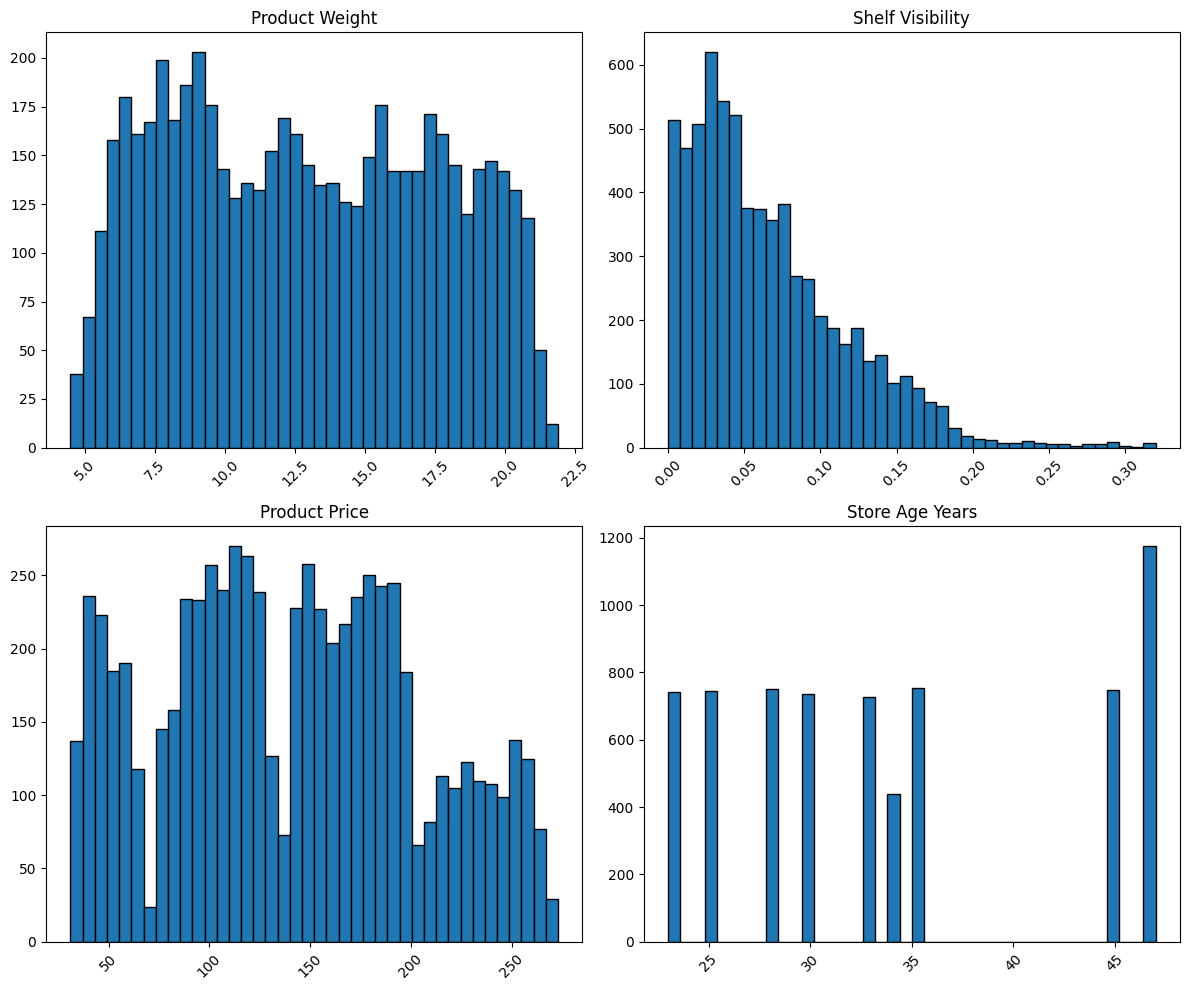

In [24]:

import matplotlib.pyplot as plt

num_cols = {
    "product_weight_kg": "Product Weight",
    "shelf_visibility": "Shelf Visibility",
    "product_price": "Product Price",
    "store_age_years": "Store Age Years"
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (col, display_name) in enumerate(num_cols.items()):
    # Added edgecolor='black' here to make the bars crisp and professional
    axes[i].hist(df[col].dropna(), bins=40, edgecolor='black')
    axes[i].set_title(display_name)
    axes[i].tick_params(axis='x', rotation=45)

for j in range(len(num_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

ii. Visualizing Categorical Distributions

Goal: I generated bar charts to examine the distribution and frequency of the categorical features.

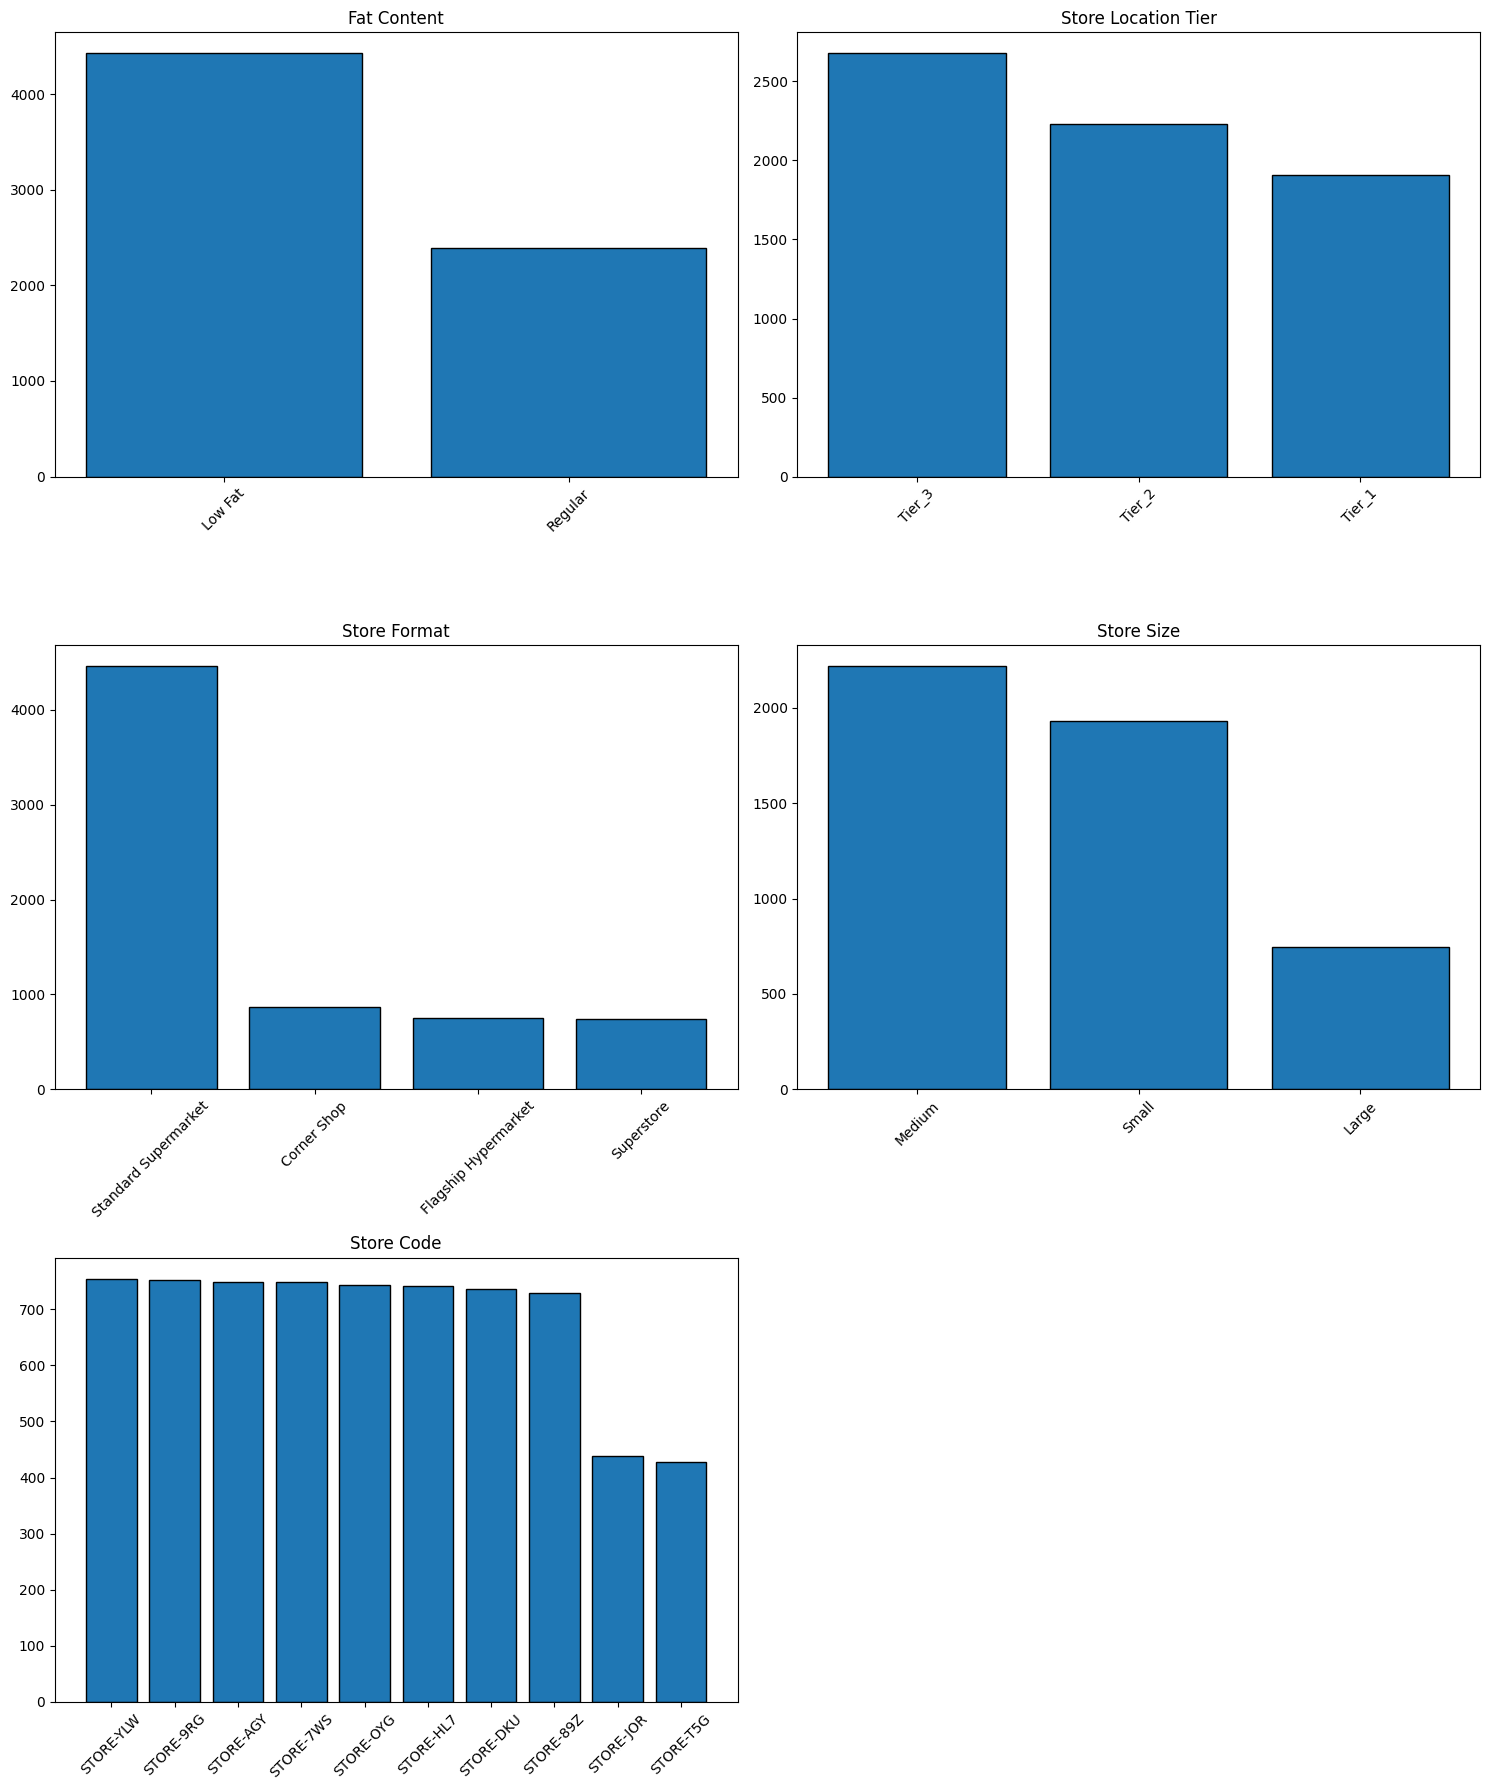

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

cat_cols = {
    "fat_content": "Fat Content",
    "store_location_tier": "Store Location Tier",
    "store_format": "Store Format",
    "store_size": "Store Size",
    "store_code": "Store Code"
}

# 3 rows, 2 columns for 5 categorical features
fig, axes = plt.subplots(3, 2, figsize=(15, 18))
axes = axes.flatten()

for i, (col, display_name) in enumerate(cat_cols.items()):
    # Get value counts for the categorical column
    counts = df[col].value_counts()

    # Plot as a bar chart
    axes[i].bar(
        counts.index,
        counts.values,
        edgecolor='black',
        color='#1f77b4'
    )

    axes[i].set_title(display_name)

    # Rotate x-ticks for better readability
    axes[i].tick_params(axis='x', rotation=45)

# Remove the unused 6th subplot
for j in range(len(cat_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig('cat_cols_user_format.png', dpi=300)
plt.show()

iii. Product_category

I plotted product category frequencies separately using a horizontal bar chart because the wide range of categories would make a combined plot difficult to read and analyze.

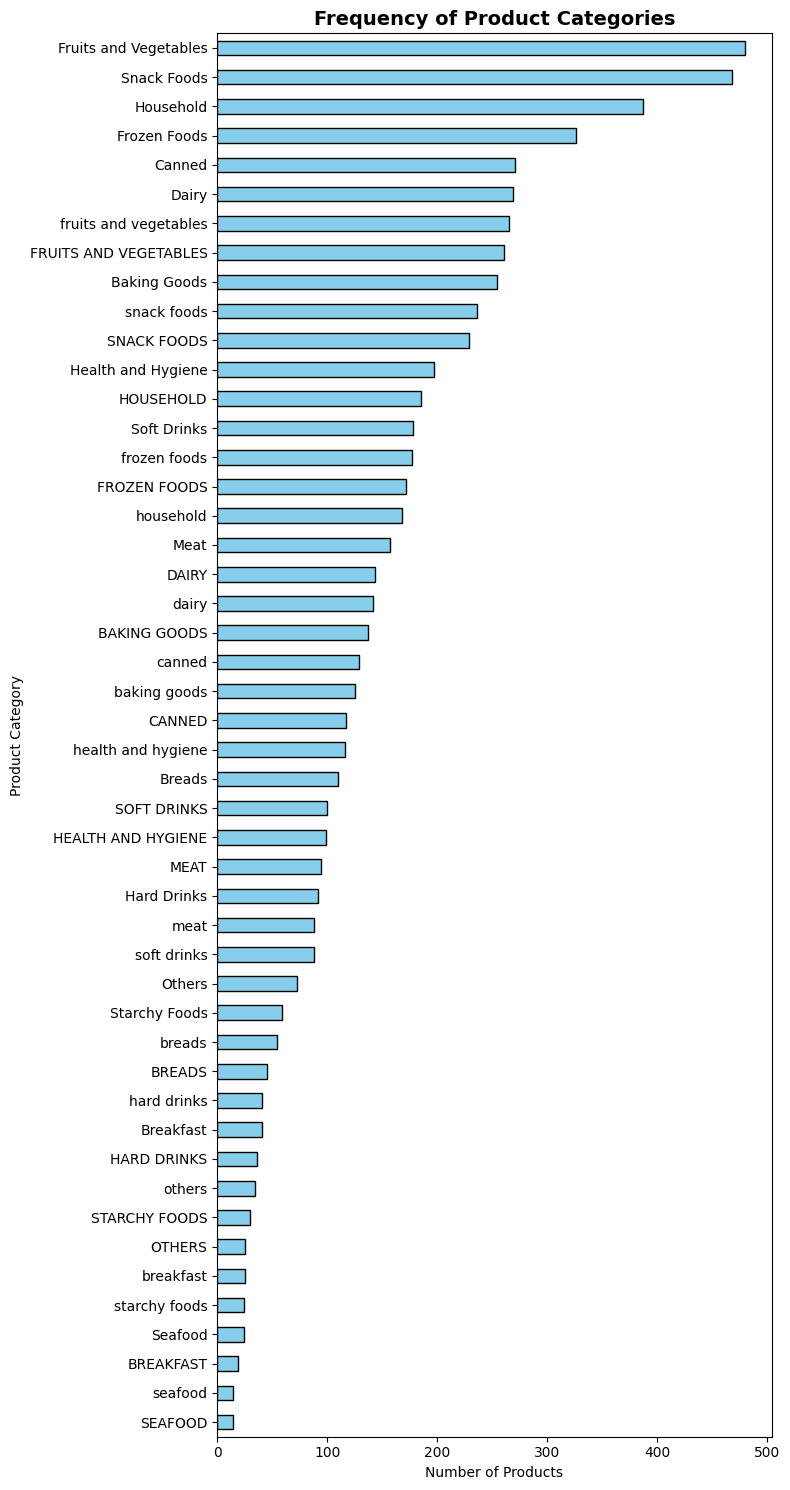

In [26]:
import matplotlib.pyplot as plt

# I used a sorted horizontal bar chart to clearly visualize the distribution of all product categories
df["product_category"].value_counts().sort_values(ascending=True).plot(
    kind="barh",
    figsize=(8, 15),
    edgecolor='black',
    color='skyblue'
)

# I added bold headers and layout adjustments for better readability
plt.title("Frequency of Product Categories", fontsize=14, fontweight='bold')
plt.xlabel("Number of Products")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

#iv. Visualization of the target  "total_sales".
#### Target Interpretation

I noticed that the `total_sales` variable is **right-skewed**, with a skewness value of **1.153**. Most observations have low to moderate sales, while a smaller number have very high sales. I tested several transformations, including log, square-root, and Yeo-Johnson, but the model using the original target produced a better RMSE. Therefore, I retained the original `total_sales` values for the final model.


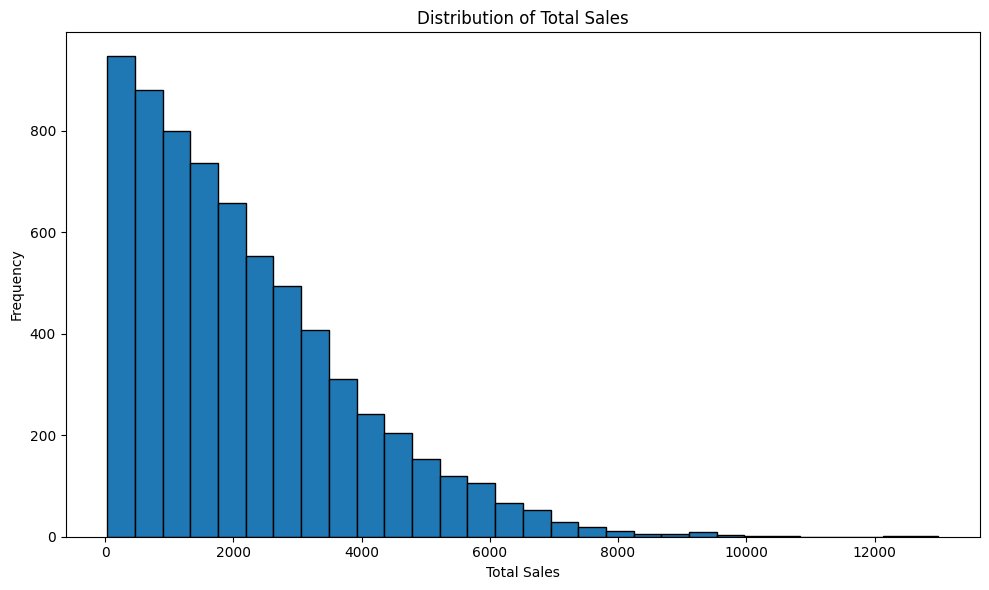

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    df["total_sales"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [28]:
df["total_sales"].skew()

np.float64(1.1539947519138116)

#v. Heatmap

####I notice from the "heatmap" that product_price has the most significant linear relationship with total_sales, showing a moderate positive correlation of 0.57. This suggests that higher-priced products tend to be associated with higher total sales volume

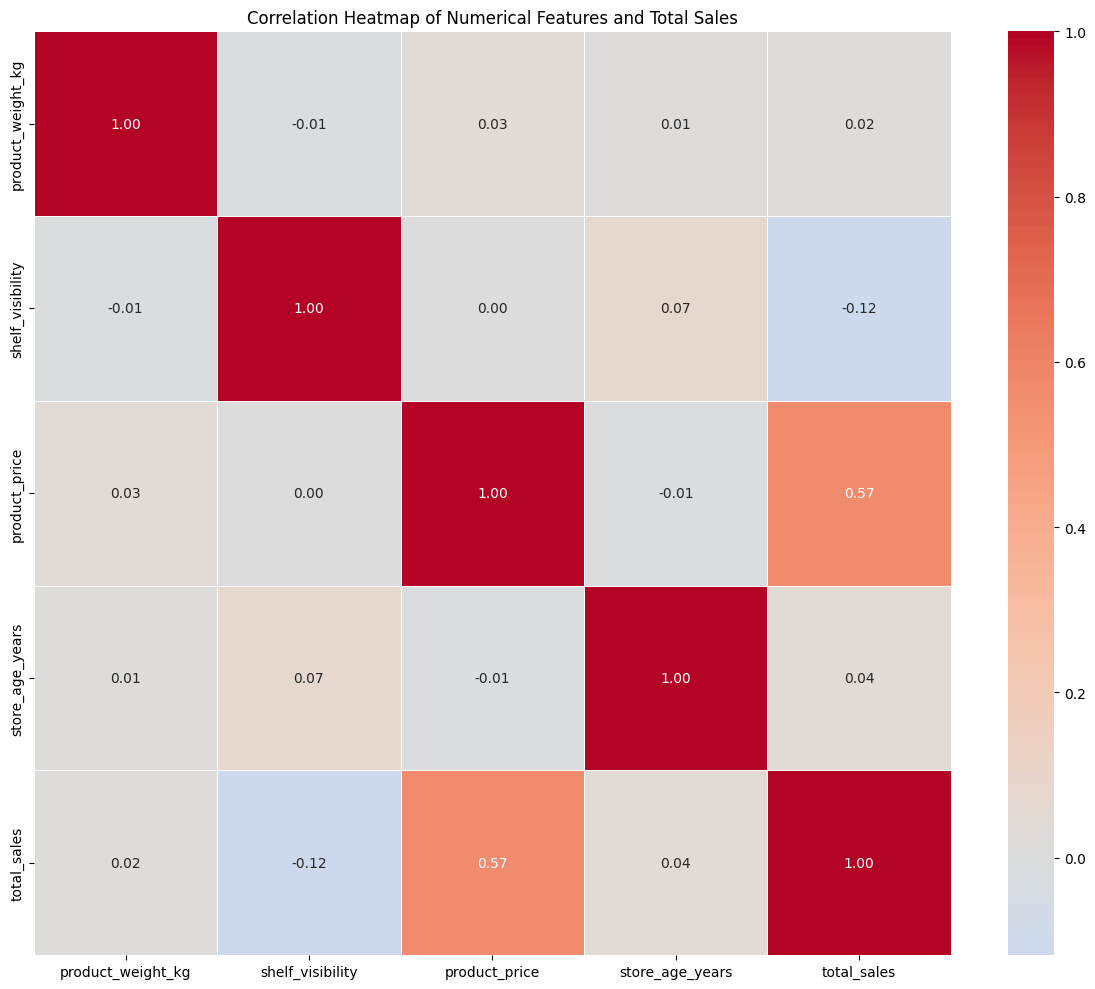

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numeric_data = df.select_dtypes(include=["number"])

# Calculate correlation matrix
correlation_matrix = numeric_data.corr()

# Plot heatmap
plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features and Total Sales")
plt.tight_layout()
plt.show()

In [30]:
#I counted the frequency of each product code to examine how products are represented across the dataset.
df['product_code'].value_counts()

,count
product_code,
PRD-YZB4K8,9
PRD-U02KQN,8
PRD-8INI8M,8
PRD-U438R9,8
PRD-ONGWUL,8
...,...
PRD-AZUAYN,1
PRD-DH3TKZ,1
PRD-AF3WE8,1


In [31]:
# I checked the unique store size values to verify the categories against the store-size dictionary.
df['store_size'].unique()

array(['Large', 'Small', 'Medium', nan], dtype=object)

In [32]:
# 1.I counted the frequency of each store size to examine how the different store sizes are represented in the dataset.
df['store_size'].value_counts()

,count
store_size,
Medium,2218
Small,1933
Large,748


In [33]:
#I examined the frequency of each store size and store code combination to understand how stores are distributed across the dataset.
df[['store_size', 'store_code']].value_counts()

store_size  store_code
Small       STORE-YLW     754
            STORE-9RG     752
Large       STORE-AGY     748
Medium      STORE-7WS     748
            STORE-HL7     742
            STORE-89Z     728
Small       STORE-T5G     427
Name: count, dtype: int64

#SUMMARY OF DATA VISUALISATION/EDA

### Dataset Interpretation

The training dataset has **6,818 rows and 13 columns**, while the test dataset has **1,705 rows and 12 columns**. The extra training column is **`total_sales`**, the target variable being predicted. Each row represents a **product sold at a specific store**.


<br> <br>


#MISSING-VALUE INTERPRETATION

The two variables with substantial missing values are:

- "product_weight_kg"
-  "store_size"

Rather than deleting these obeservvations, the modeling pipeline s hadle thm automatically and since the missing g values are not much  product_weight_kg it missing value is approximately 17.97% and for the store_size the missing value is approximately 28.15%.


#3. Analyse

I separated the target variable from the predictor variables and grouped the predictors into **numerical** and **categorical** variables.

The `id` column was excluded because it only identifies each observation and does not provide useful information about sales.


In [34]:
TRAIN_PATH = "/data/train.csv"
TEST_PATH = "/data/test.csv"

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

print("Train shape:", train.shape)
print("Test shape :", test.shape)

display(train.head())


Train shape: (6818, 13)
Test shape : (1705, 12)


,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales
0,row_00000,PRD-PRFP9S,14.252,Low Fat,0.0271,Frozen Foods,81.37,STORE-AGY,45,Large,Tier_3,Standard Supermarket,1764.98
1,row_00001,PRD-PXXK71,7.698,Low Fat,0.0720,HEALTH AND HYGIENE,42.05,STORE-YLW,35,Small,Tier_1,Standard Supermarket,342.13
2,row_00002,PRD-V5MOIJ,14.264,Regular,0.0421,Canned,41.35,STORE-89Z,33,Medium,Tier_1,Standard Supermarket,378.85
3,row_00003,PRD-UN5Z3J,NaN,Regular,0.0449,soft drinks,174.35,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket,5595.72
4,row_00004,PRD-6RDQYB,10.338,Regular,0.0120,meat,203.06,STORE-9RG,28,Small,Tier_2,Standard Supermarket,2375.36


In [35]:
# Display the columns in the dataset
print(" Columns ")
print(train.columns.tolist())

# Display the data type of each column
print("\nData Types")
display(train.dtypes.rename("dtype").to_frame())

# Display the number of missing values in each column
print("\n=== Missing Values ===")
display(train.isnull().sum().rename("missing_values").to_frame())

 Columns 
['id', 'product_code', 'product_weight_kg', 'fat_content', 'shelf_visibility', 'product_category', 'product_price', 'store_code', 'store_age_years', 'store_size', 'store_location_tier', 'store_format', 'total_sales']

Data Types


,dtype
id,object
product_code,object
product_weight_kg,float64
fat_content,object
shelf_visibility,float64
product_category,object
product_price,float64
store_code,object
store_age_years,int64
store_size,object



=== Missing Values ===


,missing_values
id,0
product_code,0
product_weight_kg,1225
fat_content,0
shelf_visibility,0
product_category,0
product_price,0
store_code,0
store_age_years,0
store_size,1919


In [36]:
TARGET = "total_sales"
ID_COL = "id"

X = train.drop(columns=[TARGET, ID_COL]).copy()
y = train[TARGET].copy()

X_test = test.drop(columns=[ID_COL]).copy()

categorical_features = X.select_dtypes(include="object").columns.tolist()
numerical_features = [c for c in X.columns if c not in categorical_features]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)


Numerical features:
['product_weight_kg', 'shelf_visibility', 'product_price', 'store_age_years']

Categorical features:
['product_code', 'fat_content', 'product_category', 'store_code', 'store_size', 'store_location_tier', 'store_format']


In [37]:
print("Unique values in categorical variables:")
for col in categorical_features:
    print(f"{col}: {X[col].nunique()} unique values")


Unique values in categorical variables:
product_code: 1555 unique values
fat_content: 2 unique values
product_category: 48 unique values
store_code: 10 unique values
store_size: 3 unique values
store_location_tier: 3 unique values
store_format: 4 unique values


#Feature Interpretation

###I observed that the dataset contains the following types of variables:

##-numerical variables
product_price
product_weight_kg
store_age_years
##-Store-level categorical variables
store_size
store_location_tier
store_format
store_code
##-Product-level categorical variables
product_category
fat_content
##-High-cardinality identifiers
product_code
Target variable
total_sales

For this reason, CatBoost is a strong model candidate for this dataset. The name CatBoost comes from Categorical Boosting, reflecting its ability to work effectively with categorical variables without requiring them to be converted into ordinary numerical values using basic encoding methods.

Another important advantage of CatBoost is that it is specifically designed to handle categorical features and relationships between categorical variables. This makes it suitable for a dataset where product and store characteristics are represented by categories.

I also observed that CatBoost internally uses ordered target statistics when processing categorical variables. This approach is designed to reduce the risk of overfitting that can occur with naive target encoding, where information from the target variable can be used too directly when encoding categories.

Therefore, based on the structure of the dataset, CatBoost was considered a strong candidate model for comparison with other machine learning models.

##Validation Strategy

<br>
I observed that an **80/20 train-validation split** was used to evaluate the models. 80% of the labelled observations were used for training, while 20% were reserved for validation. Since the validation data was not used during training, **RMSE and MAE provide out-of-sample measures of model performance**.


In [38]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training rows  :", len(X_train))
print("Validation rows:", len(X_valid))


Training rows  : 5454
Validation rows: 1364


#4. MODEL

Several regression models are compared:

1. Mean prediction baseline
2. KNN
3. GRADIENT BOOSTING
4. RANDOM FOREST
5. EXTRA TREES
6. LIGHTGBM
7. CATBOOST

The comparison shows whether the more advanced models improve performance over the simpler baseline models.

In [39]:
# Store model evaluation results
results = []

# Calculate the mean of the training target
mean_target = y_train.mean()

# Predict the training mean for every validation observation
baseline_predictions = np.repeat(mean_target, len(y_valid))

# Calculate RMSE
baseline_rmse = np.sqrt(mean_squared_error(
    y_valid,
    baseline_predictions
))

# Calculate MAE
baseline_mae = mean_absolute_error(
    y_valid,
    baseline_predictions
)



# Save the baseline results
results.append({
    "Model": "Mean Baseline",
    "RMSE": baseline_rmse,
    "MAE": baseline_mae,
})

# Display results
print(f"Baseline RMSE:     {baseline_rmse:.2f}")
print(f"Baseline MAE:      {baseline_mae:.2f}")



Baseline RMSE:     1716.87
Baseline MAE:      1354.24


###Baseline interpretation

The mean baseline produced an RMSE of approximately 1,716.87 and a MAE approximately 1354.24

<br>
The baseline provides a **reference point** for evaluating whether the trained models achieve meaningful improvement.


In [40]:
# Preprocessing for KNN
knn_preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numerical_features
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]),
        categorical_features
    )
])

# KNN model
knn_model = Pipeline([
    ("preprocessor", knn_preprocessor),
    ("model", KNeighborsRegressor(
        n_neighbors=10,
        weights="distance",
        n_jobs=-1
    ))
])

# Train
knn_model.fit(X_train, y_train)

# Predict
knn_pred = knn_model.predict(X_valid)

# Calculate metrics
knn_rmse = np.sqrt(mean_squared_error(y_valid, knn_pred))
knn_mae = mean_absolute_error(y_valid, knn_pred)

# Store results
results.append({
    "Model": "KNN",
    "RMSE": knn_rmse,
    "MAE": knn_mae
})

# Display results
print(f"KNN RMSE: {knn_rmse:.2f}")
print(f"KNN MAE : {knn_mae:.2f}")

KNN RMSE: 1110.86
KNN MAE : 792.16


###Baseline interpretation

I also tried another baseline model KNN. The mean baseline produced an RMSE of approximately
1110.86 and a MAE approximately 792.16 which performed better than mean baseline

<br>
The baseline provides a "reference point" for evaluating whether the trained models achieve meaningful improvement.


In [41]:
# Preprocessing for tree ensembles
tree_preprocessor = ColumnTransformer([
    (
        "num",
        SimpleImputer(strategy="median"),
        numerical_features
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ))
        ]),
        categorical_features
    )
])

rf_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=5,
        max_features=0.8,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_valid)

rf_rmse = np.sqrt(mean_squared_error(y_valid, rf_pred))
rf_mae = mean_absolute_error(y_valid, rf_pred)

results.append({
    "Model": "Random Forest",
    "RMSE": rf_rmse,
    "MAE": rf_mae
})

print(f"Random Forest RMSE: {rf_rmse:.2f}")
print(f"Random Forest MAE : {rf_mae:.2f}")


Random Forest RMSE: 1084.83
Random Forest MAE : 766.06


#Random Forest Regressor interpretation
### Random Forest Regression Interpretation

Random Forest provides a **non-linear tree-based model** that can capture more complex relationships between the features and sales.

Its RMSE is approximately **1,084.83**, showing how well it performs compared with the simpler baseline models. The model can capture non-linear patterns that a linear model may not represent effectively.



In [42]:
et_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", ExtraTreesRegressor(
        n_estimators=400,
        min_samples_leaf=4,
        max_features=0.9,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

et_model.fit(X_train, y_train)
et_pred = et_model.predict(X_valid)

et_rmse = np.sqrt(mean_squared_error(y_valid, et_pred))
et_mae = mean_absolute_error(y_valid, et_pred)

results.append({
    "Model": "Extra Trees",
    "RMSE": et_rmse,
    "MAE": et_mae
})

print(f"Extra Trees RMSE: {et_rmse:.2f}")
print(f"Extra Trees MAE : {et_mae:.2f}")


Extra Trees RMSE: 1084.01
Extra Trees MAE : 766.33


### Extra Trees Regression Interpretation

Extra Trees provides a **non-linear tree-based model** that can capture complex relationships between the features and sales.

Its RMSE is approximately **1,084.01**, showing a **small improvement** over the Random Forest model. This suggests that Extra Trees captures the underlying patterns and feature interactions slightly better.


In [43]:
# Prepare data for LightGBM
X_lgb = X.copy()

for col in categorical_features:
    X_lgb[col] = X_lgb[col].fillna("Missing").astype("category")

for col in numerical_features:
    X_lgb[col] = X_lgb[col].fillna(X_lgb[col].median())

X_train_lgb, X_valid_lgb, y_train_lgb, y_valid_lgb = train_test_split(
    X_lgb,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

lgb_model = LGBMRegressor(
    n_estimators=1200,
    learning_rate=0.04,
    num_leaves=15,
    max_depth=6,
    min_child_samples=30,
    subsample=0.9,
    colsample_bytree=0.9,
    reg_lambda=5,
    random_state=RANDOM_STATE,
    verbosity=-1
)

lgb_model.fit(
    X_train_lgb,
    y_train_lgb,
    categorical_feature=categorical_features,
    eval_set=[(X_valid_lgb, y_valid_lgb)],
    callbacks=[
        early_stopping(100, verbose=False),
        log_evaluation(0)
    ]
)

lgb_pred = lgb_model.predict(
    X_valid_lgb,
    num_iteration=lgb_model.best_iteration_
)

lgb_rmse = np.sqrt(mean_squared_error(y_valid_lgb, lgb_pred))
lgb_mae = mean_absolute_error(y_valid_lgb, lgb_pred)

results.append({
    "Model": "LightGBM",
    "RMSE": lgb_rmse,
    "MAE": lgb_mae
})

print("Best iteration:", lgb_model.best_iteration_)
print(f"LightGBM RMSE: {lgb_rmse:.2f}")
print(f"LightGBM MAE : {lgb_mae:.2f}")


Best iteration: 111
LightGBM RMSE: 1071.39
LightGBM MAE : 764.24


### LightGBM Regression Interpretation

LightGBM provides an **efficient gradient-boosting model** that can capture complex, non-linear relationships between the features and sales.

Its RMSE is approximately **1,071.39**, showing a **clear improvement** over the previous model. This reduction in error is encouraging and suggests that LightGBM is capturing the underlying patterns in the data more effectively.


In [44]:
# Preprocessing for Gradient Boosting
gb_preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        numerical_features
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ))
        ]),
        categorical_features
    )
])

# Gradient Boosting model
gb_model = Pipeline([
    ("preprocessor", gb_preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=600,
        learning_rate=0.06,
        max_depth=3,
        min_samples_leaf=5,
        loss="squared_error",
        random_state=RANDOM_STATE
    ))
])

# Train the model
gb_model.fit(X_train, y_train)

# Make validation predictions
gb_pred = gb_model.predict(X_valid)

# Calculate metrics
gb_rmse = np.sqrt(mean_squared_error(y_valid, gb_pred))
gb_mae = mean_absolute_error(y_valid, gb_pred)

# Store results
results.append({
    "Model": "Gradient Boosting",
    "RMSE": gb_rmse,
    "MAE": gb_mae
})

# Display results
print(f"Gradient Boosting RMSE: {gb_rmse:.2f}")
print(f"Gradient Boosting MAE : {gb_mae:.2f}")

Gradient Boosting RMSE: 1094.86
Gradient Boosting MAE : 777.89


### Gradient Boosting Regression Interpretation

Gradient Boosting is a **non-linear boosting model** that can capture complex relationships between the features and sales.

Its RMSE is approximately **1,094.86**, showing **poorer performance** than the previous model, with an increase in RMSE. This indicates that Gradient Boosting did not improve the prediction error for this dataset.


In [45]:
# Prepare CatBoost data
X_cat = X.copy()

for col in categorical_features:
    X_cat[col] = X_cat[col].fillna("Missing").astype(str)

for col in numerical_features:
    X_cat[col] = X_cat[col].fillna(X_cat[col].median())

X_train_cat, X_valid_cat, y_train_cat, y_valid_cat = train_test_split(
    X_cat,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

cat_model = CatBoostRegressor(
    iterations=650,
    depth=7,
    learning_rate=0.025,
    l2_leaf_reg=5,
    loss_function="RMSE",
    random_seed=RANDOM_STATE,
    verbose=False
)

cat_model.fit(
    X_train_cat,
    y_train_cat,
    cat_features=categorical_features,
    eval_set=(X_valid_cat, y_valid_cat),
    early_stopping_rounds=80,
    verbose=False
)

cat_pred = cat_model.predict(X_valid_cat)

cat_rmse = np.sqrt(mean_squared_error(y_valid_cat, cat_pred))
cat_mae = mean_absolute_error(y_valid_cat, cat_pred)

results.append({
    "Model": "CatBoost",
    "RMSE": cat_rmse,
    "MAE": cat_mae
})

print("Best iteration:", cat_model.get_best_iteration())
print(f"CatBoost RMSE: {cat_rmse:.2f}")
print(f"CatBoost MAE : {cat_mae:.2f}")


Best iteration: 272
CatBoost RMSE: 1062.58
CatBoost MAE : 757.78


### CatBoost Regression Interpretation

CatBoost is a **gradient-boosting model designed to handle categorical variables effectively**, making it well suited to datasets with many categorical features.

**RMSE ≈ 1,062.58**

**MAE ≈ 757.58**
######better performance than the previous models. This improvement is encouraging and may be related to CatBoost's ability to capture patterns and relationships within the dataset's categorical features.


,Model,RMSE,MAE
0,CatBoost,1062.577560,757.778505
1,LightGBM,1071.392610,764.236479
2,Extra Trees,1084.013917,766.325343
3,Random Forest,1084.834496,766.064462
4,Gradient Boosting,1094.859120,777.889908
5,KNN,1110.859989,792.163989
6,Mean Baseline,1716.866299,1354.243717


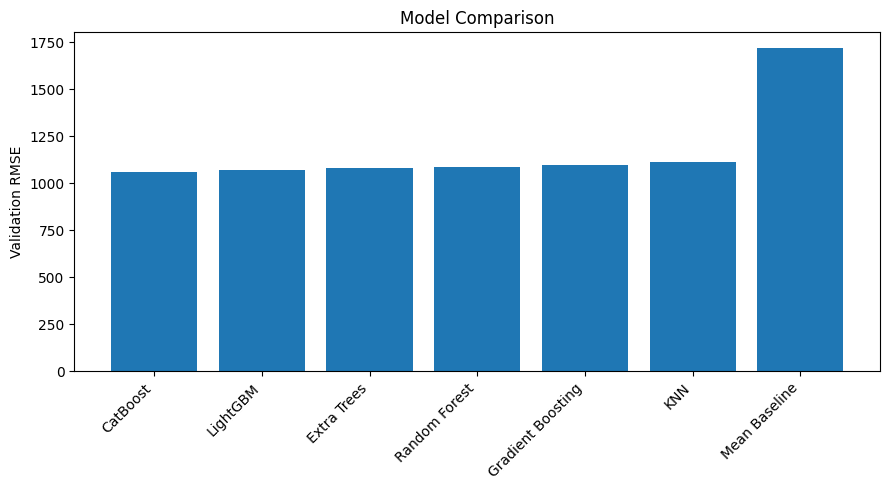

In [46]:
results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df)

plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Validation RMSE")
plt.title("Model Comparison")
plt.tight_layout()
plt.show()


## Model comparison

On the fixed 20% holdout split, the approximate results are:

| Model | RMSE |
|---|---:|
| CatBoost | **1,062.58** |
| LightGBM | **1,071.39** |
| Extra Trees | **1,084.01** |
| Random Forest | **1,084.83** |
|GradientBoost  | **1,094.86** |
| KNN Baseline | **1,110.86** |
| Mean Baseline | **1,716.87** |

I observed that **CatBoost achieved the lowest validation RMSE**, so I selected it as the final standard machine-learning model.

The improvement over the mean baseline shows that the available features contain useful predictive information. However, its RMSE is still higher than the reconstruction result because the model relies only on the supplied features.


## Feature importance

CatBoost feature importance shows **which predictors have the greatest influence on the model's predictions**.


,feature,importance
5,product_price,57.757108
10,store_format,18.812804
6,store_code,9.439098
8,store_size,3.112676
4,product_category,2.804666
9,store_location_tier,2.577424
7,store_age_years,2.109094
0,product_code,1.362870
3,shelf_visibility,0.931362
1,product_weight_kg,0.636320


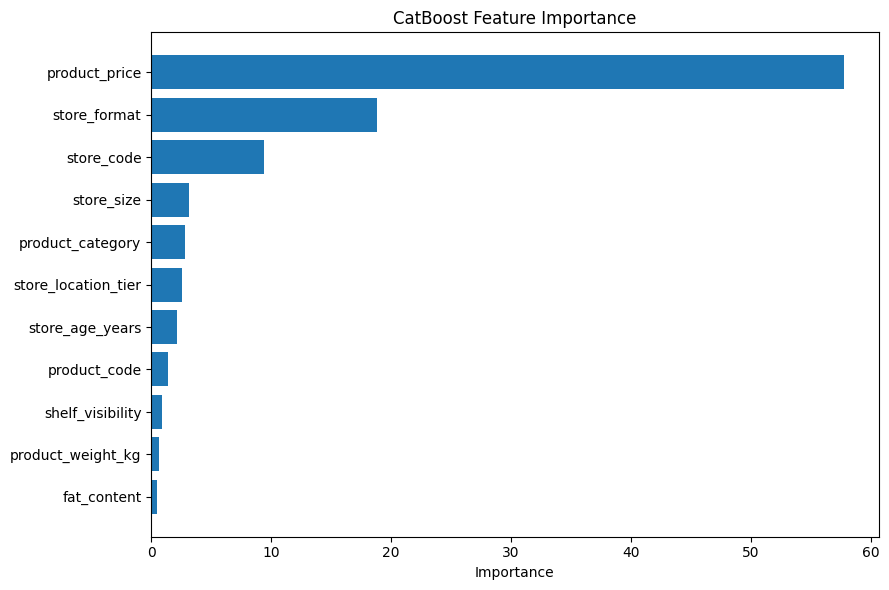

In [47]:
feature_importance = pd.DataFrame({
    "feature": X_cat.columns,
    "importance": cat_model.get_feature_importance()
}).sort_values("importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(9, 6))
plt.barh(
    feature_importance["feature"][::-1],
    feature_importance["importance"][::-1]
)
plt.xlabel("Importance")
plt.title("CatBoost Feature Importance")
plt.tight_layout()
plt.show()


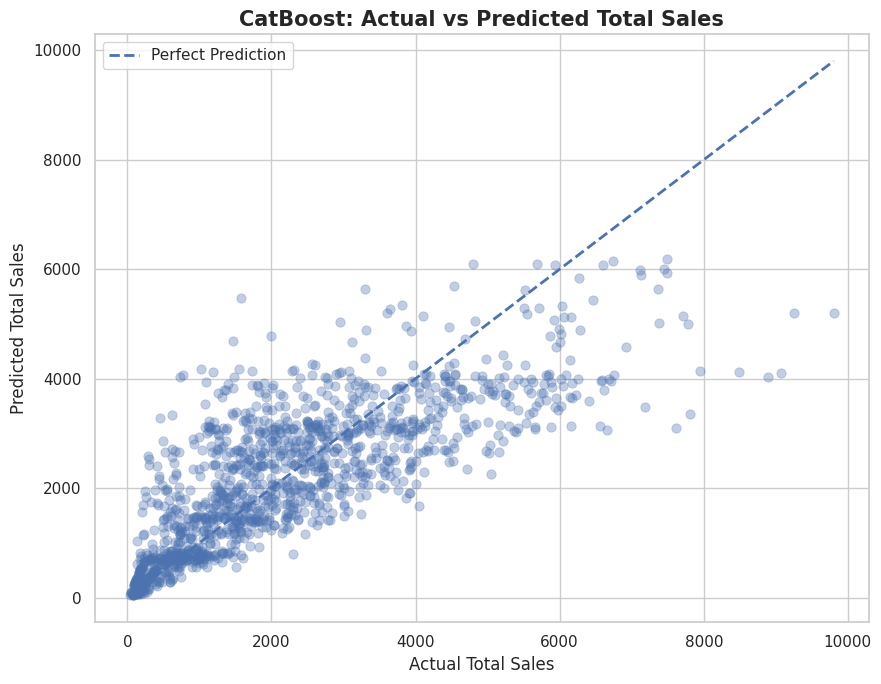

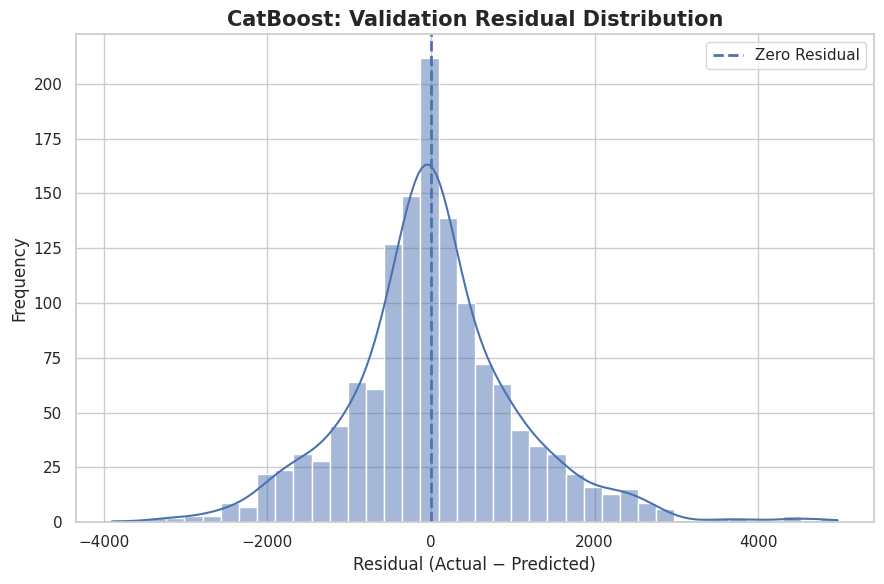

In [48]:

sns.set_theme(
    style="whitegrid",
    context="notebook"
)
residuals = y_valid_cat.to_numpy() - cat_pred

plt.figure(figsize=(9, 7))

sns.scatterplot(
    x=y_valid_cat,
    y=cat_pred,
    alpha=0.35,
    s=45,
    edgecolor=None
)
min_val = min(y_valid_cat.min(), cat_pred.min())
max_val = max(y_valid_cat.max(), cat_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Total Sales", fontsize=12)
plt.ylabel("Predicted Total Sales", fontsize=12)
plt.title(
    "CatBoost: Actual vs Predicted Total Sales",
    fontsize=15,
    fontweight="bold"
)

plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))

sns.histplot(
    residuals,
    bins=40,
    kde=True
)
plt.axvline(
    0,
    linestyle="--",
    linewidth=2,
    label="Zero Residual"
)

plt.xlabel("Residual (Actual − Predicted)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.title(
    "CatBoost: Validation Residual Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.legend()
plt.tight_layout()
plt.show()

### Validation Interpretation

I observed that the **actual-versus-predicted plot** shows how closely the model's predictions match the actual sales values. Points closer to the 45-degree line represent more accurate predictions, while points further away indicate larger prediction errors.

I also observed that the model captures the **general relationship between the product-store features and sales**. However, the spread of points around the 45-degree line shows that the model cannot predict every observation accurately, and some uncertainty remains.

The **residual distribution** provides another way to examine these prediction errors. A **positive residual** means that the actual sales were higher than the predicted sales, while a **negative residual** means that the model predicted sales higher than the actual value.

Overall, the plots show that the model is capturing useful patterns in the data, but **some observation-level prediction error remains**. This is a limitation of using the available features to predict sales and does not necessarily indicate an error in the model or code.


Since catboost work well on the featurew i will be uysing it has my model for trainng fso here i getting my feature engineeringh ready

---



Note after i have tested different kinds of models to know the model that  best fit for training my dataset and i found out that catboost work well to i decide to build up a feature engineering from my feature in other to use it and make prediction for my dataset

# 5. FEATURE ENGINEERING, PREPROCESSING, RANDOMIZED SEARCH, AND CATBOOST MODEL TRAINING


In [49]:
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor, Pool
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, RandomizedSearchCV
from scipy.stats import randint, uniform


def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Applies all feature engineering steps to a dataframe.
    Works on both train and test sets.
    Returns a new dataframe with all engineered features added.

    Parameters
    ----------
    df : pd.DataFrame
        Raw dataframe containing the original columns.

    Returns
    -------
    pd.DataFrame
        Dataframe with engineered features appended.
    """

    df = df.copy()

    # --------------------------------------------------------
    # STEP 1 — CLEAN MESSY CATEGORIES
    # Standardises the 48-variant product_category column
    # down to 16 clean categories
    # --------------------------------------------------------
    df["product_category"] = df["product_category"].str.lower().str.strip()


    # --------------------------------------------------------
    # STEP 2 — IMPUTE MISSING VALUES
    # product_weight_kg : median per product_code, then global median
    # store_size        : lookup from store_code, then mode per store_format
    # --------------------------------------------------------
    df["product_weight_kg"] = df.groupby("product_code")["product_weight_kg"] \
        .transform(lambda x: x.fillna(x.median()))
    df["product_weight_kg"] = df["product_weight_kg"].fillna(
        df["product_weight_kg"].median()
    )

    store_size_map = (
        df.dropna(subset=["store_size"])
        .drop_duplicates("store_code")
        .set_index("store_code")["store_size"]
    )
    df["store_size"] = df["store_size"].fillna(
        df["store_code"].map(store_size_map)
    )

    format_size_mode = df.groupby("store_format")["store_size"].agg(
        lambda x: x.value_counts().idxmax() if x.notna().any() else "Medium"
    )
    df["store_size"] = df["store_size"].fillna(
        df["store_format"].map(format_size_mode)
    )


    # --------------------------------------------------------
    # STEP 3 — ORDINAL ENCODING
    # Converts ordered categories into meaningful numbers
    # so the model understands the rank between them
    # --------------------------------------------------------
    df["store_size_ordinal"] = df["store_size"].map(
        {"Small": 0, "Medium": 1, "Large": 2}
    )
    df["store_tier_ordinal"] = df["store_location_tier"].map(
        {"Tier_1": 1, "Tier_2": 2, "Tier_3": 3}
    )
    df["fat_content_binary"] = (df["fat_content"] == "Low Fat").astype(int)
    df["is_flagship"]        = (df["store_format"] == "Flagship Hypermarket").astype(int)


    # --------------------------------------------------------
    # STEP 4 — NUMERICAL INTERACTION FEATURES
    # Captures how features combine to influence sales
    # --------------------------------------------------------
    df["price_per_weight"]       = df["product_price"] / df["product_weight_kg"]
    df["price_x_visibility"]     = df["product_price"] * df["shelf_visibility"]
    df["weight_x_visibility"]    = df["product_weight_kg"] * df["shelf_visibility"]
    df["price_visibility_ratio"] = df["product_price"] / (df["shelf_visibility"] + 1e-5)


    # --------------------------------------------------------
    # STEP 5 — STORE AGE BINNING
    # Groups store age into meaningful life-stage buckets
    # Converted to str so CatBoost treats it as categorical
    # --------------------------------------------------------
    df["store_age_bin"] = pd.cut(
        df["store_age_years"],
        bins=[0, 25, 33, 40, 50],
        labels=["Very New", "New", "Established", "Mature"]
    ).astype(str)


    # --------------------------------------------------------
    # STEP 6 — FREQUENCY ENCODING
    # For high-cardinality columns (product_code, store_code),
    # encodes how often each value appears in the dataset
    # --------------------------------------------------------
    df["product_code_freq"] = df["product_code"].map(
        df["product_code"].value_counts()
    )
    df["store_code_freq"] = df["store_code"].map(
        df["store_code"].value_counts()
    )


    # --------------------------------------------------------
    # STEP 7 — AGGREGATE / GROUP STATISTICS
    # Creates store-level and category-level context features
    # --------------------------------------------------------
    df["cat_avg_price"]            = df.groupby("product_category")["product_price"].transform("mean")
    df["store_avg_price"]          = df.groupby("store_code")["product_price"].transform("mean")
    df["store_avg_visibility"]     = df.groupby("store_code")["shelf_visibility"].transform("mean")
    df["price_deviation_from_cat"] = df["product_price"] - df["cat_avg_price"]

    return df

# Ensure essential variables are defined and updated for engineered features
# (These might have been defined in previous cells, but we redefine for robustness
# and to ensure they reflect the engineered data for CatBoost training)
TARGET = "total_sales"
ID_COL = "id"
RANDOM_STATE = 42 # Defined in QXg4RMBMT_Cv
TRAIN_PATH = "/data/train.csv" # Defined in NuYbtwG78jDq
TEST_PATH = "/data/test.csv" # Defined in NuYbtwG78jDq

# Re-load the train data to ensure it's clean for feature engineering
train_df_raw = pd.read_csv(TRAIN_PATH)
# Apply the previously defined feature engineering function
train_df_engineered = engineer_features(train_df_raw)

# Define X and y for the engineered features
X = train_df_engineered.drop(columns=[TARGET, ID_COL], errors='ignore').copy()
y = train_df_engineered[TARGET].copy()

# Redefine categorical and numerical features based on the engineered X
# Dynamically identify categorical features including 'object' and 'category' dtypes
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
# Dynamically identify numerical features (int64 and float64)
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()



for col in categorical_features:
    X[col] = X[col].astype(str)

print("Preprocessing complete.")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Categorical features:", categorical_features)


# ============================================================
# RANDOMIZED SEARCH CV — HYPERPARAMETER TUNING
# ============================================================

param_distributions = {
    "iterations": randint(200, 1000),
    "learning_rate": uniform(0.01, 0.29),
    "depth": randint(4, 10),
    "l2_leaf_reg": uniform(1, 10),
    "bagging_temperature": uniform(0, 1),
    "random_strength": uniform(0, 1),
    "min_data_in_leaf": randint(1, 50),
}

base_model = CatBoostRegressor(
    loss_function="RMSE",
    eval_metric="RMSE",
    # Removed cat_features from constructor to avoid cloning issue (resolved in previous interaction)
    random_seed=RANDOM_STATE,
    verbose=False,
    allow_writing_files=False,
    thread_count=4,
)

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

random_search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_distributions,
    n_iter=5, # Reduced from 50 for faster execution
    cv=kf,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)

print("\nRunning Randomized Search...")
# Pass cat_features to the fit method
random_search.fit(X, y, cat_features=categorical_features)

best_params = random_search.best_params_

print("\n" + "=" * 60)
print("RANDOMIZED SEARCH RESULTS")
print("=" * 60)
print("Best Parameters:")
for param, value in best_params.items():
    print(f"  {param}: {value}")
print(f"\nBest CV RMSE: {-random_search.best_score_:.4f}")


# ============================================================
# CROSS-VALIDATION WITH BEST PARAMS
# Prints RMSE and MSE per fold + mean and std
# ============================================================

print("\n" + "=" * 60)
print("CROSS-VALIDATION WITH BEST PARAMETERS")
print("=" * 60)

cv_model = CatBoostRegressor(
    **best_params,
    loss_function="RMSE",
    eval_metric="RMSE",
    cat_features=categorical_features,
    random_seed=RANDOM_STATE,
    verbose=False,
    allow_writing_files=False,
    thread_count=4,
)

rmse_scores = []
mse_scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X, y), 1):

    X_fold_train = X.iloc[train_idx]
    X_fold_val = X.iloc[val_idx]
    y_fold_train = y.iloc[train_idx]
    y_fold_val = y.iloc[val_idx]

    cv_model.fit(
        X_fold_train,
        y_fold_train,
        eval_set=(X_fold_val, y_fold_val),
        early_stopping_rounds=50,
        verbose=False,
    )

    y_pred = cv_model.predict(X_fold_val)

    mse = mean_squared_error(y_fold_val, y_pred)
    rmse = np.sqrt(mse)

    rmse_scores.append(rmse)
    mse_scores.append(mse)

    print(f"  Fold {fold} — RMSE: {rmse:.4f} | MSE: {mse:.4f}")

print()
print(f"  Mean RMSE : {np.mean(rmse_scores):.4f}  ±  {np.std(rmse_scores):.4f}")
print(f"  Mean MSE  : {np.mean(mse_scores):.4f}  ±  {np.std(mse_scores):.4f}")


# ============================================================
# FINAL TRAINING ON 100% OF TRAINING DATA
# No eval set — uses all available data
# ============================================================

print("\n" + "=" * 60)
print("FINAL MODEL — TRAINING ON 100% OF TRAINING DATA")
print("=" * 60)

final_model = CatBoostRegressor(
    **best_params,
    loss_function="RMSE",
    eval_metric="RMSE",
    cat_features=categorical_features,
    random_seed=RANDOM_STATE,
    verbose=100,
    allow_writing_files=False,
    thread_count=4,
)

final_model.fit(X, y)

print()
print(f"Final model trained on {X.shape[0]} samples ({X.shape[1]} features).")
print("Ready for prediction on test set.")

Preprocessing complete.
X shape: (6818, 26)
y shape: (6818,)
Categorical features: ['product_code', 'fat_content', 'product_category', 'store_code', 'store_size', 'store_location_tier', 'store_format', 'store_age_bin']

Running Randomized Search...
Fitting 5 folds for each of 5 candidates, totalling 25 fits

RANDOMIZED SEARCH RESULTS
Best Parameters:
  bagging_temperature: 0.09997491581800289
  depth: 6
  iterations: 287
  l2_leaf_reg: 4.337086111390218
  learning_rate: 0.05143137719736283
  min_data_in_leaf: 3
  random_strength: 0.020584494295802447

Best CV RMSE: 1082.2118

CROSS-VALIDATION WITH BEST PARAMETERS
  Fold 1 — RMSE: 1070.4798 | MSE: 1145927.0730
  Fold 2 — RMSE: 1051.1985 | MSE: 1105018.2199
  Fold 3 — RMSE: 1091.6448 | MSE: 1191688.2724
  Fold 4 — RMSE: 1112.8611 | MSE: 1238459.8357
  Fold 5 — RMSE: 1068.1689 | MSE: 1140984.7550

  Mean RMSE : 1078.8706  ±  21.3036
  Mean MSE  : 1164415.6312  ±  46141.5786

FINAL MODEL — TRAINING ON 100% OF TRAINING DATA
0:	learn: 1647.9

### CatBoost Training Results

The CatBoost model achieved a **mean RMSE of 1,078.87 ± 21.30** across the cross-validation folds. The corresponding **mean MSE was 1,164,415.63 ± 46,141.58**. The standard deviations indicate the variation in model performance across the validation folds.


#FEATURE IMPORTANCE

FULL FEATURE IMPORTANCE SUMMARY
Rank  Feature                           PVC Score    LFC Score     Status
----------------------------------------------------------------------
1     product_price                       21.5236     246.3733       ✓ OK
2     store_avg_visibility                16.9594      17.9767       ✓ OK
3     store_avg_price                     16.7784      28.6346       ✓ OK
4     store_code_freq                     11.7457       5.1097       ✓ OK
5     store_format                         7.9593      26.9557       ✓ OK
6     price_deviation_from_cat             6.9466      28.3131       ✓ OK
7     store_age_years                      3.8799       1.4484       ✓ OK
8     price_per_weight                     1.6101       4.6870       ✓ OK
9     product_category                     1.5393       4.6196       ✓ OK
10    is_flagship                          1.4666       0.8920       ✓ OK
11    product_weight_kg                    1.2847       3.8987       ✓ OK
12    sto

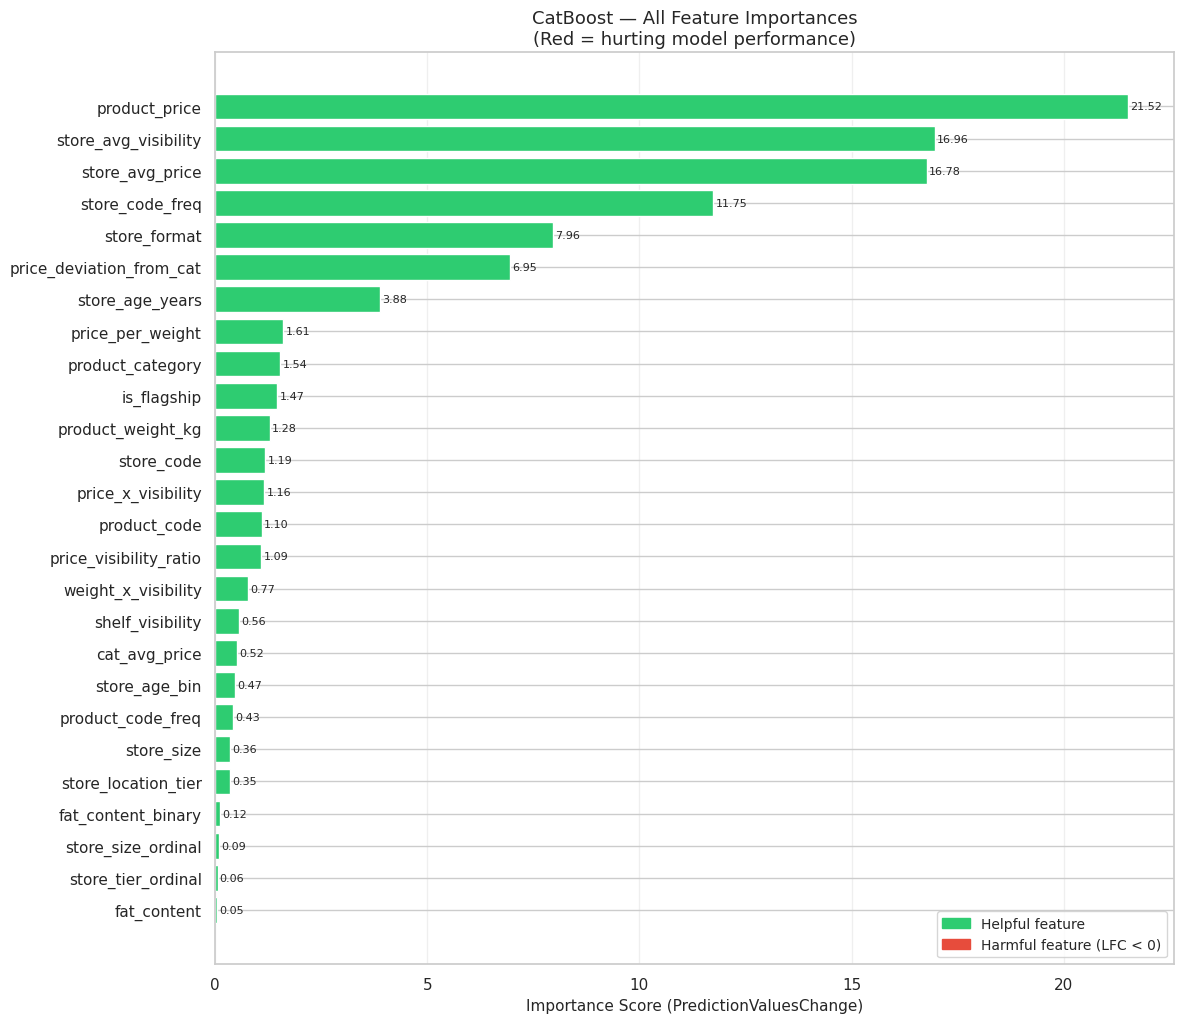

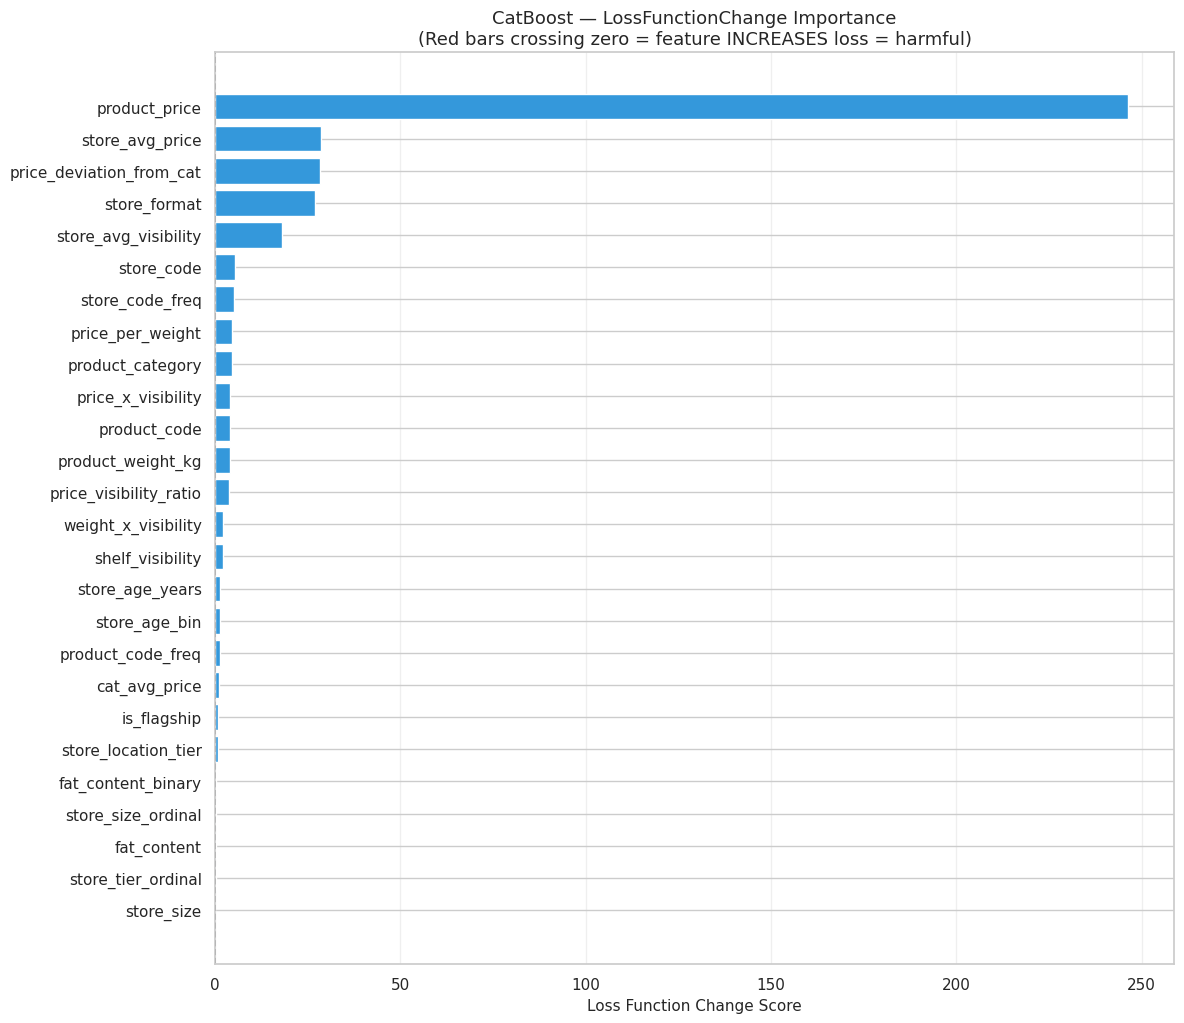


✓ No harmful features detected. All features are contributing positively.


In [50]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np
from catboost import Pool

# BUILD POOL FOR IMPORTANCE CALCULATION

train_pool = Pool(
    data         = X,
    label        = y,
    cat_features = categorical_features
)


# IMPORTANCE TYPE 1 — PredictionValuesChange (default)
# How much each feature moves the prediction value
# All scores are positive — higher = more influential

pvc_scores = final_model.get_feature_importance(
    data = train_pool,
    type = "PredictionValuesChange"
)

pvc_df = pd.DataFrame({
    "Feature"    : final_model.feature_names_,
    "PVC_Score"  : pvc_scores
}).sort_values("PVC_Score", ascending=False).reset_index(drop=True)


# IMPORTANCE TYPE 2 — LossFunctionChange
# Measures how much the LOSS changes when a feature is removed
# NEGATIVE score = feature increases loss = HURTS the model

lfc_scores = final_model.get_feature_importance(
    data = train_pool,
    type = "LossFunctionChange"
)

lfc_df = pd.DataFrame({
    "Feature"    : final_model.feature_names_,
    "LFC_Score"  : lfc_scores
}).sort_values("LFC_Score", ascending=True).reset_index(drop=True)


# MERGE BOTH INTO ONE SUMMARY TABLE

summary_df = pvc_df.merge(lfc_df, on="Feature")
summary_df["Harmful"] = summary_df["LFC_Score"] < 0
summary_df = summary_df.sort_values("PVC_Score", ascending=False).reset_index(drop=True)
summary_df["Rank"] = summary_df.index + 1

print("=" * 70)
print("FULL FEATURE IMPORTANCE SUMMARY")
print("=" * 70)
print(f"{'Rank':<5} {'Feature':<30} {'PVC Score':>12} {'LFC Score':>12} {'Status':>10}")
print("-" * 70)
for _, row in summary_df.iterrows():
    status = "⚠ HARMFUL" if row["Harmful"] else "✓ OK"
    print(
        f"{int(row['Rank']):<5} "
        f"{row['Feature']:<30} "
        f"{row['PVC_Score']:>12.4f} "
        f"{row['LFC_Score']:>12.4f} "
        f"{status:>10}"
    )


# PLOT 1 — ALL FEATURES (PredictionValuesChange)
# Colour: green = helpful | red = harmful

plot_df = summary_df.sort_values("PVC_Score", ascending=True)

colors = [
    "#e74c3c" if harmful else "#2ecc71"
    for harmful in plot_df["Harmful"]
]

plt.figure(figsize=(12, max(6, len(plot_df) * 0.4)))

bars = plt.barh(
    plot_df["Feature"],
    plot_df["PVC_Score"],
    color    = colors,
    edgecolor= "white",
)

for bar, val in zip(bars, plot_df["PVC_Score"]):
    plt.text(
        val + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.2f}",
        va       = "center",
        fontsize = 8,
    )

green_patch = mpatches.Patch(color="#2ecc71", label="Helpful feature")
red_patch   = mpatches.Patch(color="#e74c3c", label="Harmful feature (LFC < 0)")

plt.legend(handles=[green_patch, red_patch], fontsize=10)
plt.xlabel("Importance Score (PredictionValuesChange)", fontsize=11)
plt.title("CatBoost — All Feature Importances\n(Red = hurting model performance)", fontsize=13)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# PLOT 2 — LossFunctionChange (shows negative harmful features)

lfc_plot = summary_df.sort_values("LFC_Score", ascending=True)

lfc_colors = [
    "#e74c3c" if v < 0 else "#3498db"
    for v in lfc_plot["LFC_Score"]
]

plt.figure(figsize=(12, max(6, len(lfc_plot) * 0.4)))

plt.barh(
    lfc_plot["Feature"],
    lfc_plot["LFC_Score"],
    color     = lfc_colors,
    edgecolor = "white",
)

plt.axvline(x=0, color="black", linewidth=1.2, linestyle="--")
plt.xlabel("Loss Function Change Score", fontsize=11)
plt.title(
    "CatBoost — LossFunctionChange Importance\n"
    "(Red bars crossing zero = feature INCREASES loss = harmful)",
    fontsize=13
)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# PRINT HARMFUL FEATURES SEPARATELY

harmful_features = summary_df[summary_df["Harmful"] == True]

print("\n" + "=" * 70)
if len(harmful_features) == 0:
    print("No harmful features detected. All features are contributing positively.")
else:
    print(f" HARMFUL FEATURES DETECTED ({len(harmful_features)} total)")
    print("=" * 70)
    print("These features have a negative LossFunctionChange score,")
    print("meaning removing them could IMPROVE model performance.\n")
    print(f"{'Feature':<30} {'PVC Score':>12} {'LFC Score':>12}")
    print("-" * 55)
    for _, row in harmful_features.iterrows():
        print(
            f"{row['Feature']:<30} "
            f"{row['PVC_Score']:>12.4f} "
            f"{row['LFC_Score']:>12.4f}"
        )
    print("\nConsider dropping these features and retraining to see if RMSE improves.")

# FEATURE ENGINEERING INTERPRETATION: All the feature engineered work well and none cause harm or is redundant.

#6. PREDICT

In [51]:

# GENERATE SUBMISSION FILE

import pandas as pd
import numpy as np
from catboost import Pool

# STEP 1 — LOAD AND ENGINEER TEST DATA

df_test = pd.read_csv("/data/test.csv")

print("Test shape (raw):", df_test.shape)
print("Test columns:", df_test.columns.tolist())

df_test = engineer_features(df_test)

print("Test shape (after engineering):", df_test.shape)

# STEP 2 — ALIGN TEST COLUMNS WITH TRAIN

DROP_COLS_TEST = ["id"]
DROP_COLS_TEST = [col for col in DROP_COLS_TEST if col in df_test.columns]

X_test = df_test.drop(columns=DROP_COLS_TEST)

for col in categorical_features:
    if col in X_test.columns:
        X_test[col] = X_test[col].astype(str)

X_test = X_test[X.columns]

print("\nX_test shape      :", X_test.shape)
print("X_train shape     :", X.shape)
print("Columns match     :", list(X_test.columns) == list(X.columns))


# STEP 3 — PREDICT WITH FINAL MODEL

test_pool = Pool(
    data         = X_test,
    cat_features = categorical_features
)

predictions = final_model.predict(test_pool)

print("\nPrediction stats:")
print(f"  Min  : {predictions.min():.3f}")   # ← changed to 3
print(f"  Max  : {predictions.max():.3f}")   # ← changed to 3
print(f"  Mean : {predictions.mean():.3f}")  # ← changed to 3
print(f"  Std  : {predictions.std():.3f}")   # ← changed to 3


# STEP 4 — BUILD SUBMISSION DATAFRAME

submission = pd.DataFrame({
    "id"          : df_test["id"],
    "total_sales" : predictions.round(3)
})

print("\nSubmission preview:")
print(submission.head(10))
print("\nSubmission shape:", submission.shape)


# STEP 5 — VALIDATE BEFORE SAVING

print("\n" + "=" * 50)
print("SUBMISSION VALIDATION")
print("=" * 50)

null_preds = submission["total_sales"].isnull().sum()
print(f"Null predictions    : {null_preds}")

neg_preds = (submission["total_sales"] < 0).sum()
print(f"Negative predictions: {neg_preds}")

if neg_preds > 0:
    print(f"  ⚠ Clipping {neg_preds} negative predictions to 0")
    submission["total_sales"] = submission["total_sales"].clip(lower=0)

print(f"Test rows           : {len(df_test)}")
print(f"Submission rows     : {len(submission)}")
print(f"Rows match          : {len(df_test) == len(submission)}")



# STEP 6 — SAVE SUBMISSION FILE

submission.to_csv("submissions.csv", index=False)

print("\n" + "=" * 50)
print("✓ submission.csv saved successfully")
print("=" * 50)
print(submission.head())

Test shape (raw): (1705, 12)
Test columns: ['id', 'product_code', 'product_weight_kg', 'fat_content', 'shelf_visibility', 'product_category', 'product_price', 'store_code', 'store_age_years', 'store_size', 'store_location_tier', 'store_format']
Test shape (after engineering): (1705, 27)

X_test shape      : (1705, 26)
X_train shape     : (6818, 26)
Columns match     : True

Prediction stats:
  Min  : 475.151
  Max  : 4676.938
  Mean : 2101.632
  Std  : 927.305

Submission preview:
          id  total_sales
0  row_00009     2571.913
1  row_00015     4456.364
2  row_00019     2174.881
3  row_00020     3094.293
4  row_00023     2285.083
5  row_00026     1647.175
6  row_00027     3601.040
7  row_00033     3396.853
8  row_00034     1361.687
9  row_00037     2283.408

Submission shape: (1705, 2)

SUBMISSION VALIDATION
Null predictions    : 0
Negative predictions: 0
Test rows           : 1705
Submission rows     : 1705
Rows match          : True

✓ submission.csv saved successfully
          

#6.Communication
The dataset represents product-store sales, where each row combines a particular product with a particular store. The target, `total_sales`, is influenced by both product and store characteristics, including `product_code`, `product_category`, `product_price`, `store_code`, `store_size`, `store_location_tier`, and `store_format`.

I observed that `total_sales` was **right-skewed**, with some products having much higher sales than others. I therefore tested transformations of the target, including square-root, cube-root, and log transformations, to see whether they would improve prediction. However, the **actual target values performed better**, so I retained the original `total_sales` rather than transforming it.

I also observed missing values, particularly in `store_size`, and treated them as missing rather than making unsupported assumptions. The available training information was then used to handle these missing values consistently before modelling.

Overall, I understood the dataset as a **product × store sales problem**, where product characteristics, store characteristics, and their interactions can influence sales. This understanding guided my cleaning, feature engineering, model validation, and final model training.
